In [1]:
import pandas as pd
import re
import shap
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

In [2]:
df = pd.read_json(
    "../Data/reviews_Clothing_Shoes_and_Jewelry.json",
    lines=True
)

In [3]:
df = df[['overall', 'reviewText']]

df = df.dropna()

df.columns = ['Score', 'Text']

df.head()

,Score,Text
0,5,Perfect red tutu for the price. I baught it as...
1,4,This was a really cute tutu the only problem i...
2,2,the tutu color was very nice. the only issue w...
3,1,My 3-yr-old daughter received this as a gift f...
4,4,Bought it for my daughters first birthday whic...


In [4]:
df = df.sample(10000, random_state=42)

df.shape

(10000, 2)

In [5]:
def convert_sentiment(score):

    if score <= 2:
        return 0

    elif score == 3:
        return 1

    else:
        return 2


df['Sentiment'] = df['Score'].apply(convert_sentiment)

df[['Score', 'Sentiment']].head()

,Score,Sentiment
1311987,5,2
5529979,4,2
3815880,5,2
2708805,4,2
3107250,5,2


In [6]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r'<.*?>', '', text)

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    return text


df['Text'] = df['Text'].apply(clean_text)

df.head()

,Score,Text,Sentiment
1311987,5,i bought these for my daughter for soccer prac...,2
5529979,4,fit and quality is very good fabric is lighte...,2
3815880,5,i just recently had major surgery on my foot a...,2
2708805,4,let me start off by saying i love these boots ...,2
3107250,5,these shoes are the best i have them in black ...,2


In [7]:
vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(df['Text'])

y = df['Sentiment']

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
models = {

    "Logistic Regression":
    LogisticRegression(max_iter=1000),

    "Naive Bayes":
    MultinomialNB(),

    "SVM":
    LinearSVC()
}


for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(name)

    print(
        "Accuracy:",
        accuracy_score(y_test, y_pred)
    )

    print("-------------------------")

Logistic Regression
Accuracy: 0.817
-------------------------
Naive Bayes
Accuracy: 0.7755
-------------------------
SVM
Accuracy: 0.8245
-------------------------


In [10]:
base_models = [

    ("lr", LogisticRegression(max_iter=1000)),

    ("nb", MultinomialNB()),

    ("svm", LinearSVC())

]

meta_model = LogisticRegression()

stack_model = StackingClassifier(

    estimators=base_models,

    final_estimator=meta_model

)

stack_model.fit(X_train, y_train)

print("Stacking Model Trained")

Stacking Model Trained


In [11]:
y_pred = stack_model.predict(X_test)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        y_pred,
        average='macro'
    )
)

print(
    "Weighted F1:",
    f1_score(
        y_test,
        y_pred,
        average='weighted'
    )
)

Accuracy: 0.826

Classification Report:

              precision    recall  f1-score   support

           0       0.59      0.58      0.58       248
           1       0.40      0.10      0.16       204
           2       0.87      0.96      0.91      1548

    accuracy                           0.83      2000
   macro avg       0.62      0.55      0.55      2000
weighted avg       0.79      0.83      0.80      2000

Macro F1: 0.5543454821801332
Weighted F1: 0.7972241852814987


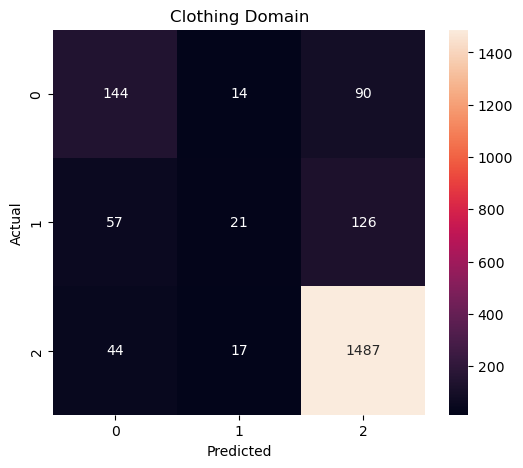

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title("Clothing Domain")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [13]:
sample = [
    "this dress quality is very bad and fitting is poor"
]

sample_vec = vectorizer.transform(sample)

prediction = stack_model.predict(sample_vec)

prediction

array([0])

In [14]:
shap.initjs()

In [15]:
X_train_dense = X_train.toarray()

X_test_dense = X_test.toarray()

In [16]:
shap_model = LogisticRegression(max_iter=1000)

shap_model.fit(
    X_train_dense,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [17]:
explainer = shap.Explainer(
    shap_model,
    X_train_dense
)

In [18]:
shap_values = explainer(
    X_test_dense[:100]
)

In [19]:
shap_values = explainer(
    X_test_dense[:100]
)

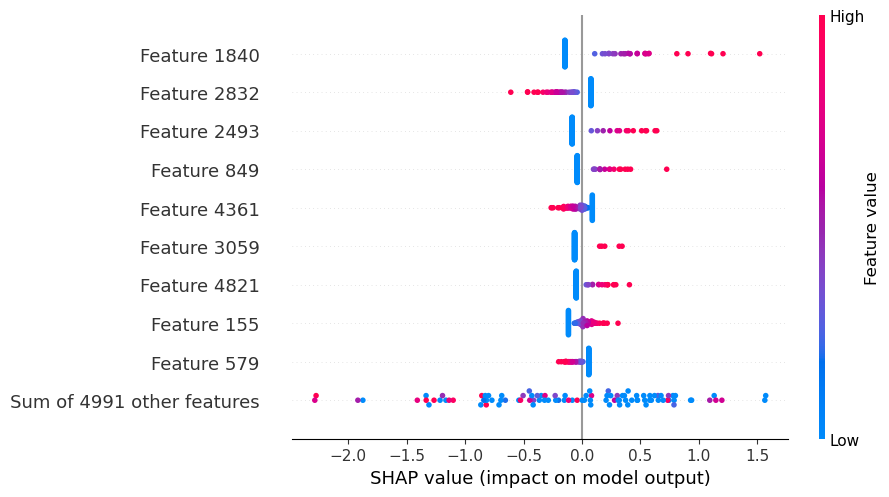

In [20]:
shap.plots.beeswarm(
    shap_values[:, :, 2]
)

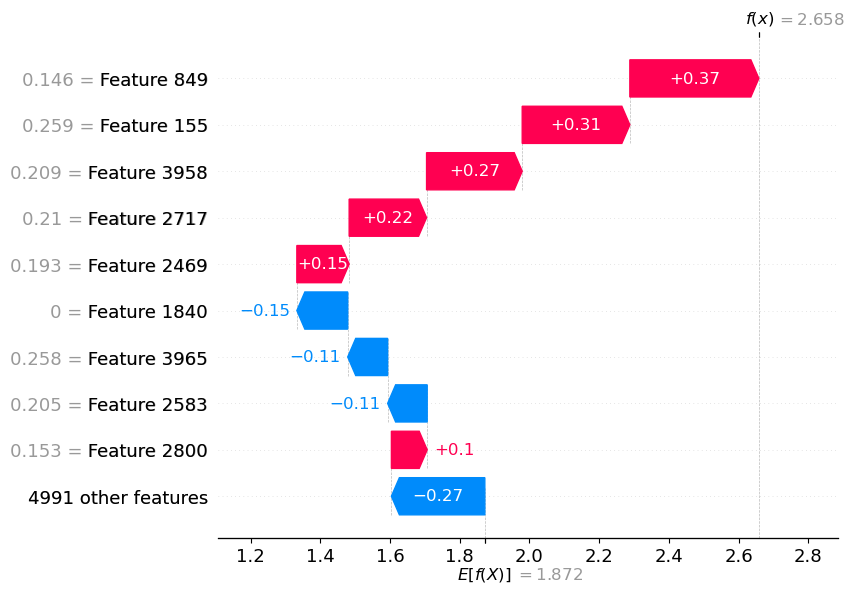

In [21]:
shap.plots.waterfall(
    shap_values[0, :, 2]
)